# Verificación de bloques patrón con micrómetro de carátula (dial)

Los bloques patrón constituyen la magnitud en verificación; el micrómetro de carátula actúa como instrumento de referencia calibrado.

**Instrumento de referencia.** Micrómetro de carátula con carátula en pulgadas: 40 vueltas por pulgada, aguja graduada en milésimas de pulgada ($0.001$ in). No posee escala métrica. Se considera calibrado, por lo que su indicación se toma como valor de referencia.

**Lectura.** La indicación se reconstruye a partir de los dos campos del registro de laboratorio:

$$L_i = \left(\frac{\text{Frac}}{40} + \text{Dial}\times 10^{-3}\right)\times 25.4\ \text{mm},$$

donde \texttt{Frac} cuenta las vueltas enteras de la aguja y \texttt{Dial} la posición de la aguja dentro de la vuelta, en milésimas de pulgada. El factor $25.4$ convierte a milímetros.

**Bloques.** Ocho bloques patrón entre $0.5$ y $25$ mm, con tres repeticiones por bloque. Para cada uno se estima su corrección como la diferencia entre la longitud indicada por el dial y la longitud nominal.

La resolución de la indicación, en milímetros, es la de una división de la aguja:

$$d = 0.001\ \text{in}\times 25.4\ \frac{\text{mm}}{\text{in}} = 25.4\ \mu\text{m}.$$


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Constantes del instrumento ---
VUELTAS_POR_PULGADA = 40       # carátula: 40 vueltas = 1 in
PASO_AGUJA_IN = 1e-3          # aguja graduada en milésimas de pulgada
MM_POR_PULGADA = 25.4

RESOLUCION_IN = PASO_AGUJA_IN
RESOLUCION_MM = RESOLUCION_IN * MM_POR_PULGADA   # 0.0254 mm = 25.4 um
print(f"Resolución: {RESOLUCION_MM*1000:.1f} um")

# --- Lecturas crudas del registro de laboratorio (Dial.xlsx) ---
# Cada fila: (patrón en mm, [(Frac, Dial)_1, (Frac, Dial)_2, (Frac, Dial)_3])
REGISTRO = [
    (0.5,  [(0, 19.60), (0, 19.70), (0, 20.45)]),
    (3.5,  [(5, 12.40), (5, 12.95), (5, 14.15)]),
    (16.5, [(26,  0.10), (26,  0.05), (26, 24.65)]),
    (15.0, [(23, 16.15), (23, 15.20), (23, 16.45)]),
    (12.0, [(18, 23.20), (18, 22.50), (18, 21.80)]),
    (23.0, [(36,  6.65), (36,  6.40), (36,  6.45)]),
    (20.5, [(32,  7.40), (32,  7.75), (32,  6.55)]),
    (25.0, [(39, 10.30), (39, 10.00), (39, 10.20)]),
]

def lectura_mm(frac, dial_milesimas):
    """Reconstruye la indicación en mm desde vueltas enteras + aguja."""
    total_in = frac / VUELTAS_POR_PULGADA + dial_milesimas * PASO_AGUJA_IN
    return total_in * MM_POR_PULGADA

filas = []
for patron, lecturas in REGISTRO:
    for p, (frac, dial) in enumerate(lecturas, start=1):
        filas.append({"VP_mm": patron, "rep": p, "Frac": frac,
                      "Dial_milesimas": dial,
                      "Lectura_mm": lectura_mm(frac, dial)})

lecturas = pd.DataFrame(filas)
lecturas["Lectura_mm"] = lecturas["Lectura_mm"].round(6)
lecturas


Resolución: 25.4 um


,VP_mm,rep,Frac,Dial_milesimas,Lectura_mm
0,0.5,1,0,19.60,0.49784
1,0.5,2,0,19.70,0.50038
2,0.5,3,0,20.45,0.51943
3,3.5,1,5,12.40,3.48996
4,3.5,2,5,12.95,3.50393
5,3.5,3,5,14.15,3.53441
6,16.5,1,26,0.10,16.51254
7,16.5,2,26,0.05,16.51127
8,16.5,3,26,24.65,17.13611
9,15.0,1,23,16.15,15.01521


## Validación de la reconstrucción

Antes de reducir los datos se comprueba que cada lectura reconstruida caiga dentro del intervalo plausible alrededor de su patrón. Una lectura de la aguja en milésimas no puede exceder una vuelta completa, y la diferencia respecto del patrón no debe superar el rango de trabajo del instrumento.

Se detecta que la tercera repetición del punto de $16.5$ mm arroja $17.136$ mm, es decir $0.636$ mm — veinticinco divisiones de la aguja — fuera del patrón. Corresponde a un registro inconsistente: \texttt{Frac} indica cero vueltas de la aguja en tanto que \texttt{Dial} marca $24.65$ milésimas, valor imposible para esa vuelta.

Esa repetición se marca como inválida y se excluye del cálculo de la media y de la desviación estándar de su propio punto, no de los demás puntos. El resto del conjunto se conserva.


In [2]:
# Tolerancia de validación: media vuelta de aguja. Una lectura fuera de este
# margen respecto del patrón no puede corresponder a una medición válida.
TOLERANCIA_MM = 0.5 * (1 / VUELTAS_POR_PULGADA) * MM_POR_PULGADA   # 0.3175 mm

lecturas["Desvio_mm"] = lecturas["Lectura_mm"] - lecturas["VP_mm"]
lecturas["Valida"] = lecturas["Desvio_mm"].abs() <= TOLERANCIA_MM

invalidas = lecturas[~lecturas["Valida"]]
print(f"Tolerancia: +-{TOLERANCIA_MM:.4f} mm")
print(f"Lecturas inválidas: {len(invalidas)}")
print(invalidas[["VP_mm", "rep", "Frac", "Dial_milesimas", "Lectura_mm", "Desvio_mm"]].to_string(index=False))

validas = lecturas[lecturas["Valida"]].copy()
validas


Tolerancia: +-0.3175 mm
Lecturas inválidas: 1
 VP_mm  rep  Frac  Dial_milesimas  Lectura_mm  Desvio_mm
  16.5    3    26           24.65    17.13611    0.63611


,VP_mm,rep,Frac,Dial_milesimas,Lectura_mm,Desvio_mm,Valida
0,0.5,1,0,19.60,0.49784,-0.00216,True
1,0.5,2,0,19.70,0.50038,0.00038,True
2,0.5,3,0,20.45,0.51943,0.01943,True
3,3.5,1,5,12.40,3.48996,-0.01004,True
4,3.5,2,5,12.95,3.50393,0.00393,True
5,3.5,3,5,14.15,3.53441,0.03441,True
6,16.5,1,26,0.10,16.51254,0.01254,True
7,16.5,2,26,0.05,16.51127,0.01127,True
9,15.0,1,23,16.15,15.01521,0.01521,True
10,15.0,2,23,15.20,14.99108,-0.00892,True


In [3]:
resumen = (
    validas.groupby("VP_mm")["Lectura_mm"]
    .agg(n="count", media="mean", s="std")
    .reset_index()
)
resumen["s"] = resumen["s"].fillna(0.0)
resumen = resumen.rename(columns={"VP_mm": "L_nominal_mm"})

# Corrección del bloque: diferencia entre lo indicado por el dial (referencia)
# y la longitud nominal del bloque.
resumen["correccion_um"] = (resumen["media"] - resumen["L_nominal_mm"]) * 1000
resumen["s_um"] = resumen["s"] * 1000
resumen["sigma_media_um"] = resumen["s_um"] / np.sqrt(resumen["n"])

resumen_print = resumen.copy()
for c in ["media", "s"]:
    resumen_print[c] = resumen_print[c].round(5)
for c in ["correccion_um", "s_um", "sigma_media_um"]:
    resumen_print[c] = resumen_print[c].round(2)
print(f"Bloques: {len(resumen)}   Repeticiones válidas: {int(resumen['n'].sum())}")
resumen_print.to_string(index=False)


Bloques: 8   Repeticiones válidas: 23


' L_nominal_mm  n    media       s  correccion_um  s_um  sigma_media_um\n          0.5  3  0.50588 0.01180           5.88 11.80            6.81\n          3.5  3  3.50943 0.02273           9.43 22.73           13.12\n         12.0  3 12.00150 0.01778           1.50 17.78           10.27\n         15.0  3 15.00971 0.01658           9.71 16.58            9.57\n         16.5  2 16.51190 0.00090          11.90  0.90            0.63\n         20.5  3 20.50373 0.01567           3.73 15.67            9.05\n         23.0  3 23.02510 0.00336          25.10  3.36            1.94\n         25.0  3 25.02323 0.00388          23.23  3.88            2.24'

## Corrección y dispersión por bloque

Para cada bloque se estima la corrección

$$c_k = \bar{L}_k - V_{P,k},$$

donde $\bar{L}_k$ es la media de las repeticiones indicadas por el dial, tomado como referencia, y $V_{P,k}$ la longitud nominal del bloque.

La dispersión de las repeticiones mide la reproducibilidad de la comparación, no una propiedad del bloque. Con dos o tres repeticiones por bloque, $s_k$ tiene una incertidumbre relativa grande (del orden del $50\%$), de modo que no debe leerse como una medida precisa.

Aun así, el agrupamiento observado es sistemático: los bloques de $16.5$, $23$ y $25$ mm presentan dispersiones por debajo de $4\ \mu\text{m}$, mientras que los restantes superan los $11\ \mu\text{m}$. Una hipótesis compatible con el mecanismo es que en las posiciones próximas a una vuelta entera de la aguja el juego de la transmisión es menor. Confirmarla requeriría más repeticiones.


In [4]:
# --- Incertidumbre de la corrección de cada bloque (todo en micrometros) ---

# 1) Reproducibilidad de la comparación: s/sqrt(n) por bloque (tipo A)
u_rep_um = resumen["sigma_media_um"].to_numpy()

# 2) Resolución de la aguja del dial: rectangular, semiamplitud a = d/2
#    sigma = a/sqrt(3) = d/(2 sqrt 3)
u_res_um = (RESOLUCION_MM * 1000) / (2 * np.sqrt(3))

# 3) Corrección certificada del dial: no consta en la fuente -> se declara nula
u_dial_um = 0.0

u_c_um = np.sqrt(u_rep_um**2 + u_res_um**2 + u_dial_um**2)
U_um = 2 * u_c_um   # factor de cobertura k = 2

L_nom = resumen["L_nominal_mm"].to_numpy()
c_um = resumen["correccion_um"].to_numpy()

tabla = pd.DataFrame({
    "L_nominal_mm": L_nom,
    "n": resumen["n"].to_numpy(),
    "correccion_um": c_um,
    "u_rep_um": u_rep_um,
    "u_res_um": np.full(L_nom.shape, u_res_um, dtype=float),
    "u_c_um": u_c_um,
    "U_um": U_um,
})
for col in tabla.columns[3:]:
    tabla[col] = tabla[col].round(2)

print(f"Resolución d = {RESOLUCION_MM*1000:.1f} um  ->  u_res = d/(2*sqrt3) = {u_res_um:.2f} um")
print("k = 2")
print()
print(tabla.to_string(index=False))
print()
print(f"Corrección media  = {c_um.mean():+.2f} um")
print(f"Corrección mínima = {c_um.min():+.2f} um")
print(f"Corrección máxima = {c_um.max():+.2f} um")
print(f"Amplitud          = {c_um.max()-c_um.min():.2f} um")
print(f"Todas del mismo signo: {bool((c_um>0).all() or (c_um<0).all())}")


Resolución d = 25.4 um  ->  u_res = d/(2*sqrt3) = 7.33 um
k = 2

 L_nominal_mm  n  correccion_um  u_rep_um  u_res_um  u_c_um  U_um
          0.5  3       5.883333      6.81      7.33   10.01 20.02
          3.5  3       9.433333     13.12      7.33   15.03 30.07
         12.0  3       1.500000     10.27      7.33   12.62 25.23
         15.0  3       9.706667      9.57      7.33   12.06 24.11
         16.5  2      11.905000      0.63      7.33    7.36 14.72
         20.5  3       3.726667      9.05      7.33   11.65 23.29
         23.0  3      25.100000      1.94      7.33    7.58 15.17
         25.0  3      23.233333      2.24      7.33    7.67 15.33

Corrección media  = +11.31 um
Corrección mínima = +1.50 um
Corrección máxima = +25.10 um
Amplitud          = 23.60 um
Todas del mismo signo: True


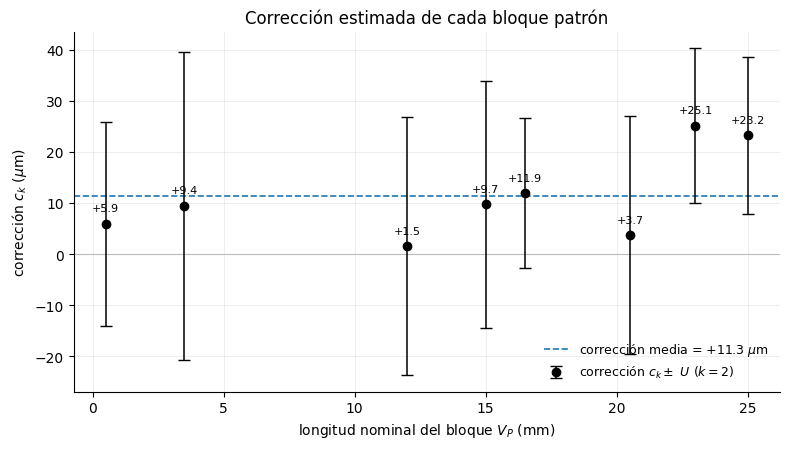

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.6))

ax.axhline(0, color="0.75", lw=0.8, zorder=1)
ax.axhline(c_um.mean(), color="C0", ls="--", lw=1.2,
           label=f"corrección media = {c_um.mean():+.1f} $\\mu$m", zorder=2)

ax.errorbar(L_nom, c_um, yerr=U_um, fmt="o", color="k", ms=6, capsize=4,
            elinewidth=1.1, label="corrección $c_k \\pm\\ U$ ($k=2$)", zorder=3)

for x, y in zip(L_nom, c_um):
    ax.annotate(f"{y:+.1f}", (x, y), textcoords="offset points",
                xytext=(0, 9), ha="center", fontsize=8)

ax.set_xlabel("longitud nominal del bloque $V_P$ (mm)")
ax.set_ylabel("corrección $c_k$ ($\\mu$m)")
ax.set_title("Corrección estimada de cada bloque patrón")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.grid(alpha=0.25, lw=0.6)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
plt.show()


## Interpretación

### Correcciones obtenidas

Las ocho correcciones resultan **positivas**, con media $\bar{c} = +11.3\ \mu\text{m}$ y amplitud de $23.6\ \mu\text{m}$ (de $+1.5$ a $+25.1\ \mu\text{m}$). La corrección crece de forma aproximada con la longitud del bloque: los dos valores mayores corresponden a $23$ y $25$ mm, y el menor a $12$ mm.

### El problema del signo sistemático

Ocho bloques patrón certificados no presentan errores del mismo signo. Un conjunto de bloques de grado $1$ en buen estado tendría correcciones de signo alternado y magnitud típica de $\pm 1$ a $\pm 2\ \mu\text{m}$. Que los ocho lean alto, y que la desviación crezca con la longitud, apunta a una causa común en el sistema de medición y no a un defecto de los bloques.

Esa causa común no puede separarse con los datos disponibles. Dos explicaciones son compatibles:

1. **El dial conserva un error de cero o de escala residual.** La corrección media de $+11.3\ \mu\text{m}$ sería su error de cero, y el crecimiento con la longitud su error de escala.
2. **El cero del dial no se materializó en las condiciones del ensayo**, por ejemplo por falta de un bloque de referencia cero o por un apoyo distinto.

Sin la corrección certificada del dial no es posible decidir entre ambas. Por esa razón **el veredicto de conformidad de los bloques no puede emitirse**: atribuir las correcciones observadas a los bloques supondría asignarles un error de cero que con toda probabilidad pertenece al instrumento.

### Compatibilidad individual con cero

Las incertidumbres expandidas cubren el intervalo de $14.7$ a $30.1\ \mu\text{m}$. Las correcciones de $0.5$, $3.5$, $12$, $15$, $16.5$ y $20.5$ mm son compatibles con cero dentro de su incertidumbre, mientras que las de $23$ y $25$ mm no lo son: sus intervalos quedan íntegramente por encima de cero.

Que dos bloques se aparten de cero mientras seis no lo hacen, y que los dos apartados sean los de mayor longitud, sostiene la interpretación de un efecto de escala del dial más que de una falta de calidad de esos bloques.

## Conclusiones

1. **Se estimaron las correcciones de los ocho bloques** con una incertidumbre expandida de $14.7$ a $30.1\ \mu\text{m}$ ($k = 2$).

2. **La corrección media es $+11.3\ \mu\text{m}$**, con los ocho valores de signo positivo. La homogeneidad del signo impide atribuir las correcciones a los bloques.

3. **No se emite veredicto de conformidad.** El experimento no permite separar el error sistemático del instrumento del error de los bloques.

4. **El efecto parece crecer con la longitud**, lo que sugiere un error de escala del dial. Se trata de una hipótesis, no de una conclusión establecida.

## Limitaciones

- **No consta la corrección certificada del dial.** Es la limitación decisiva: sin ella, el experimento mide la suma de dos errores y no puede repartirla.

- **No se registró temperatura.** A $25$ mm y con $\Delta T = 1.5\ ^\circ\text{C}$, la corrección térmica alcanza $0.4\ \mu\text{m}$, despreciable frente a la incertidumbre, pero la hipótesis debe declararse.

- **Las incertidumbres del certificado de los bloques no constan.** Se adopta $\sigma(V_P) = 0$, lo que subestima la incertidumbre de la corrección.

- **Tres repeticiones por bloque** dan una estimación de $s$ con incertidumbre relativa del orden del $50\%$.

- **Una de las veinticuatro lecturas del registro es imposible** según la lógica de la escala: $\texttt{Frac} = 26$ con $\texttt{Dial} = 24.65$ milésimas arroja $17.14$ mm frente a un bloque de $16.5$ mm. Se excluyó de su propio bloque; quedan $23$ lecturas válidas.
